<center><p float="center">
  
</p></center>

<center><font size=10><b>Restaurant Review Analysis Using LLM </b></center></font>


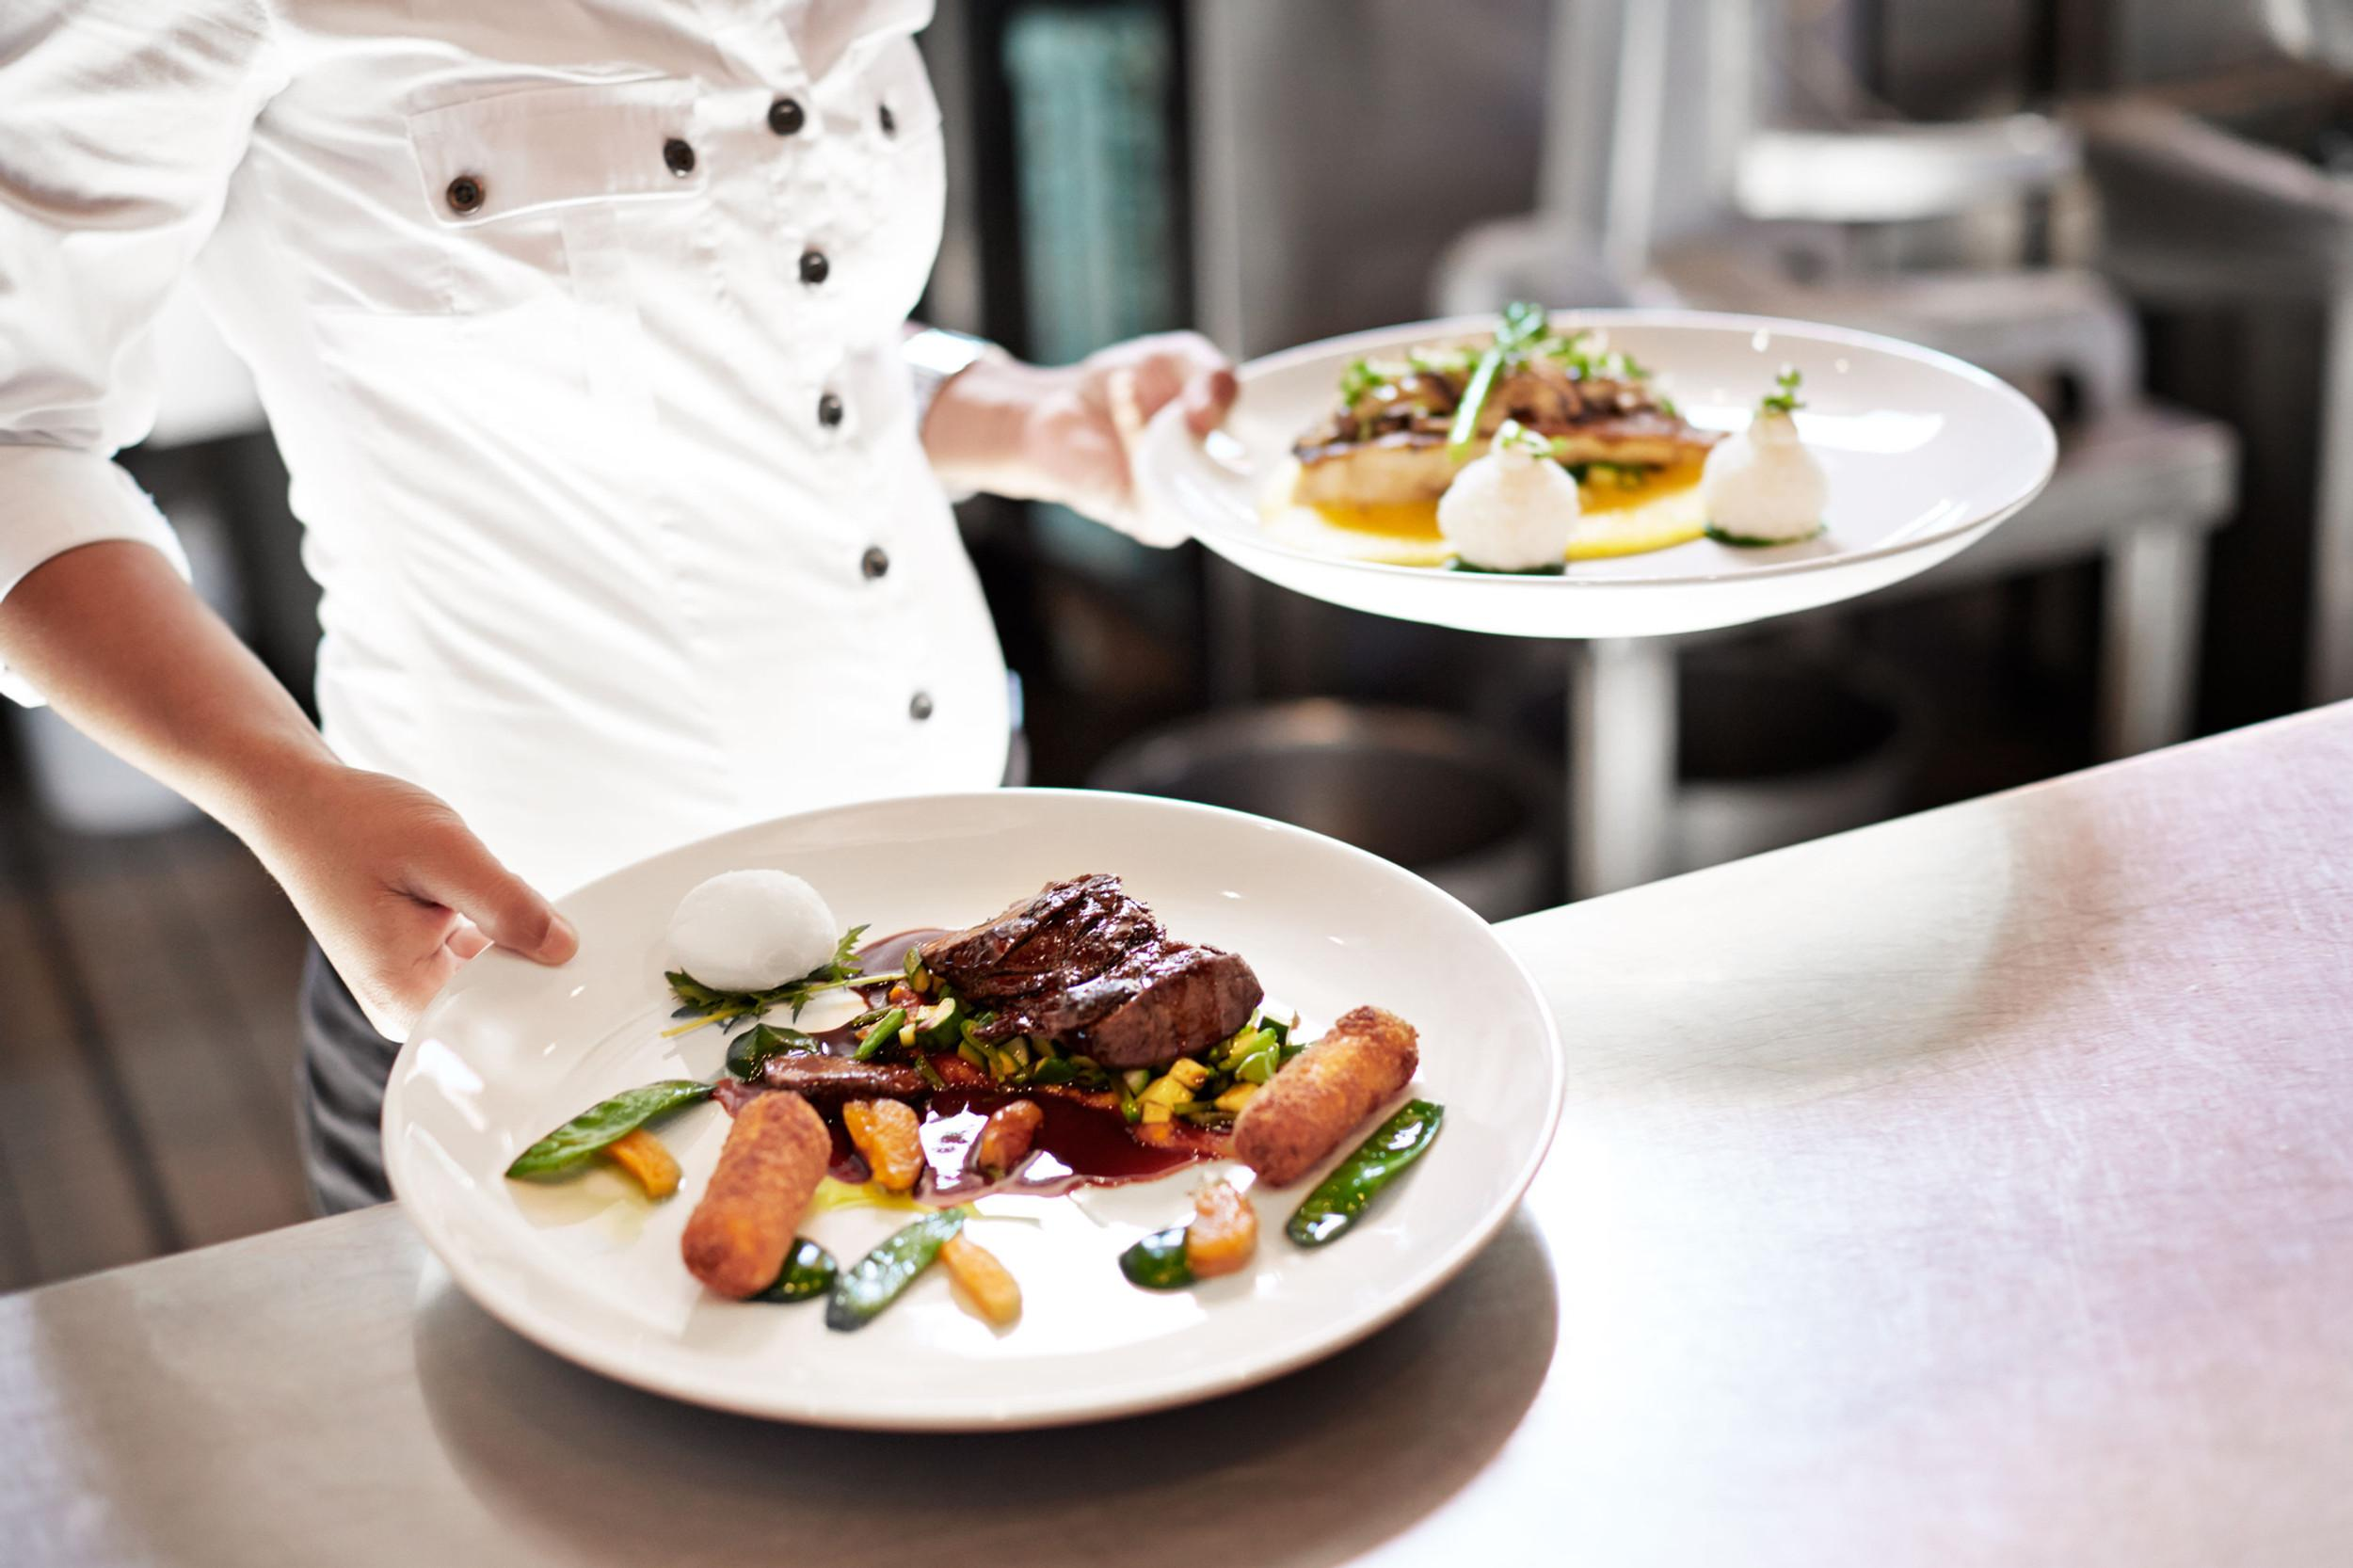

## Problem Statement

### Business Context

Customer satisfaction is a key factor in the success of restaurants and food delivery platforms. A leading global food aggregator aims to analyze customer reviews to understand customer experiences, identify areas for improvement, and enhance overall service quality. The insights gained will help improve restaurant performance and increase customer satisfaction.

### Objective


The objective is to develop an **LLM-based sentiment analysis system** using **prompt engineering** to analyze restaurant reviews. The system identifies the overall sentiment (positive, negative, or neutral), performs aspect-level sentiment analysis for food, service, and ambience, and extracts liked and disliked features. This helps restaurants understand customer feedback, improve service quality, and enhance customer satisfaction.


### Data Dictionary

The dataset comprises three columns:

1. **restaurant\_id** – Unique identifier for each restaurant.
2. **rating\_review** – Numerical or categorical rating provided by the customer.
3. **review\_full** – Complete customer review text.


## Installing and Importing Necessary Libraries

In [ ]:
!pip install -q transformers==4.53.2 \
                  accelerate==1.8.1 \
                  bitsandbytes==0.46.1

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.9/40.9 kB 1.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 69.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 365.3/365.3 kB 16.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.9/72.9 MB 10.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 23.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 80.5 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.20.0 requires huggingface-hub<2.0,>=1.2.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [ ]:
import pandas as pd
import json
import os
from transformers import AutoTokenizer, AutoModelForCausalLM

## Import the dataset

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
data = pd.read_csv("/content/drive/MyDrive/Dataset/GenAIDataset/restaurant_reviews.csv")

## Data Overview

In [ ]:
# checking the first five rows of the data
data.head()

,restaurant_ID,rating_review,review_full
0,FLV202,5,"Totally in love with the Auro of the place, re..."
1,SAV303,5,Kailash colony is brimming with small cafes no...
2,YUM789,5,Excellent taste and awesome decorum. Must visi...
3,TST101,5,I have visited at jw lough/restourant. There w...
4,EAT456,5,Had a great experience in the restaurant food ...


In [ ]:
data.shape

(20, 3)

**Observation**
- The dataset contains **20 restaurant reviews with 3 columns (restaurant_ID, rating_review, and review_full)** for sentiment analysis.


In [ ]:
# checking for missing values
data.isnull().sum()

,0
restaurant_ID,0
rating_review,0
review_full,0


**Observations**

- There are no missing values in the data

In [ ]:
# creating a copy of the data
df = data.copy()

# Model Loading

In [ ]:
file_name = '/content/drive/MyDrive/Dataset/GenAIDataset/config.json'
with open(file_name, 'r') as file:
    config = json.load(file)
    HF_TOKEN = config.get("HF_TOKEN")


# Store API credentials in environment variables
os.environ['HF_TOKEN'] = HF_TOKEN


In [ ]:
import torch

model_id = "mistralai/Mistral-7B-Instruct-v0.1"

tokenizer = AutoTokenizer.from_pretrained(model_id)

model = AutoModelForCausalLM.from_pretrained(
    model_id,
    load_in_8bit=True,  # Load the model with 8-bit quantization
    torch_dtype=torch.float16,         # Use 16-bit floats on GPU
    device_map="auto",                 # Automatically assign GPU or CPU
    token=HF_TOKEN
)

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json: 0.00B [00:00, ?B/s]

tokenizer.model:   0%|          | 0.00/493k [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/414 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/571 [00:00<?, ?B/s]

... (3 outputs left out)

model-00002-of-00002.safetensors:   0%|          | 0.00/4.54G [00:00<?, ?B/s]

model-00001-of-00002.safetensors:   0%|          | 0.00/9.94G [00:00<?, ?B/s]

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/116 [00:00<?, ?B/s]


* **`load_in_8bit=True`**: Loads the model in **8-bit precision** to reduce memory usage.
* **`torch_dtype=torch.float16`**: Uses **16-bit floating-point precision** for faster and more efficient computation.
* **`device_map="auto"`**: Automatically assigns the model across available CPU/GPU devices for optimal performance.


In [ ]:
# Define the prompt (question)
prompt = "### Question: What is the capital of France?\n### Answer:"

# Tokenize input
inputs = tokenizer(prompt, return_tensors="pt").to(model.device)

# Generate response
outputs = model.generate(**inputs)

# Decode and print the output
response = tokenizer.decode(outputs[0], skip_special_tokens=True)
print(response)

Setting `pad_token_id` to `eos_token_id`:2 for open-end generation.


### Question: What is the capital of France?
### Answer: Paris


In [ ]:
def query_mistral(prompt, query):
    """
    Queries the Mistral model with a given prompt and query.

    Args:
        prompt (str): The prompt for the model.
        query (str): The query to be answered by the model.

    Returns:
        str: The model's response.
    """
    messages = [
        {"role": "system", "content": prompt},
        {"role": "user", "content": query}
    ]
    inputs = tokenizer.apply_chat_template(messages, return_tensors="pt").to(model.device)

    pad_token_id = tokenizer.pad_token_id or tokenizer.eos_token_id

    attention_mask = (inputs != pad_token_id).long()

    outputs = model.generate(
        inputs,
        attention_mask=attention_mask,
        max_new_tokens=300,  # Adjust as needed
        do_sample=True,
        temperature=0.7,     # Adjust as needed
        top_p=0.9,           # Adjust as needed
        pad_token_id=pad_token_id  # Prevents warning
    )

    # Decode and print the output, skipping the input tokens
    response = tokenizer.decode(outputs[0][inputs.shape[-1]:], skip_special_tokens=True)
    return response




**Before Generation**

1. **`tokenizer.apply_chat_template()`**: Formats the chat messages into the model's required input format and converts them into tokens.
2. **`pad_token_id`**: Specifies the padding token used during generation; if unavailable, it uses the end-of-sequence (`eos_token_id`).
3. **`attention_mask`**: Tells the model which tokens to process (1) and which padding tokens to ignore (0).

**Generation Parameters**

1. **`max_new_tokens=100`**: Limits the model to generating a maximum of **100 new tokens**.
2. **`temperature=0.7`**: Controls randomness; **0.7** produces balanced, natural, and slightly creative responses.
3. **`do_sample=True`**: Enables token sampling, making the output more varied instead of always choosing the highest-probability token.
4. **`top_p=0.9`**: Uses **nucleus sampling**, selecting tokens from the smallest group whose combined probability is **90%**, balancing creativity and coherence.


# Reviews Sentiment Analysis

## 1. Overall Sentiment Analysis

In [ ]:
# defining the instructions for the model
instruction_1 = """
    You are an AI analyzing restaurant reviews. Classify the sentiment of the provided review into the following categories:
    - Positive
    - Negative
    - Neutral

    And return in only JSON format. No extra text and analysis
    {"Sentiment":"Positive"}
"""

In [ ]:
def classify_sentiment(prompt, query):
    try:
        response_text = query_mistral(prompt, query)
        # Attempt to parse the response text as JSON
        classification_result = json.loads(response_text)
        return classification_result
    except json.JSONDecodeError as e:
        print(f"Error decoding JSON from OpenAI response: {e}")
        print(f"Raw OpenAI response: {response_text}")
        return None
    except Exception as e:
        print(f"An unexpected error occurred: {e}")
        return None



In [ ]:
# Apply the classification function to each row in the DataFrame
df['Sentiment'] = df['review_full'].apply(lambda x: classify_sentiment(instruction_1, x)['Sentiment'] if classify_sentiment(instruction_1, x) else None)

In [ ]:
df

,restaurant_ID,rating_review,review_full,Sentiment
0,FLV202,5,"Totally in love with the Auro of the place, re...",Positive
1,SAV303,5,Kailash colony is brimming with small cafes no...,Positive
2,YUM789,5,Excellent taste and awesome decorum. Must visi...,Positive
3,TST101,5,I have visited at jw lough/restourant. There w...,Positive
4,EAT456,5,Had a great experience in the restaurant food ...,Positive
5,RST-A1,5,We came across Perch by accident and had dinne...,Positive
6,DSH404,5,We went there on birthday special time. A nice...,Negative
7,GRT505,3,Our visit to Green Bites on a busy Saturday ev...,Neutral
8,MMM606,3,"At Bella Cuisine, the cozy atmosphere and frie...",Neutral
9,FST707,3,Our dinner at Spice Haven provided a neutral e...,Neutral


In [ ]:
df['Sentiment'].value_counts()

,count
Sentiment,
Negative,8
Positive,6
Neutral,6


Across the different restaurants, negative sentiment slightly outweighs positive and neutral feedback, indicating more dissatisfaction overall.


## 2. Sentiment toward Different Aspects of the Experience

In [ ]:
# defining the instructions for the model
instruction_2 = """
    You are an AI analyzing restaurant reviews. Classify the following aspects in the review and classify the sentiment of each aspect as "Positive", "Negative", or "Neutral":
    1. "Food Quality"
    2. "Service"
    3. "Ambience"

    Output the overall sentiment and sentiment for each category in a JSON format with the following keys:
    {
        "Food Quality": "your_sentiment_prediction",
        "Service": "your_sentiment_prediction",
        "Ambience": "your_sentiment_prediction"
    }

    In case one of the three aspects is not mentioned in the review, set "Not Applicable" (including quotes) for the corresponding JSON key value.
    Only return the JSON, do not return any other information.
"""

In [ ]:
def classify_aspect_sentiment(prompt, query):
    """
    Classifies the sentiment of aspects of the review using the Mistral model
    and returns the result as a JSON object.

    Args:
        prompt (str): The prompt for the model (instruction_2).
        query (str): The review text.

    Returns:
        dict: A dictionary containing the sentiment classification for each aspect,
              or None if JSON decoding fails.
    """
    try:
        response_text = query_mistral(prompt, query)
        # Attempt to parse the response text as JSON
        classification_result = json.loads(response_text)
        return classification_result
    except json.JSONDecodeError as e:
        print(f"Error decoding JSON from model response: {e}")
        print(f"Raw model response: {response_text}")
        return None
    except Exception as e:
        print(f"An unexpected error occurred: {e}")
        return None

In [ ]:
# Apply the classification function to each row in the DataFrame
df['aspect_sentiment'] = df['review_full'].apply(lambda x: classify_aspect_sentiment(instruction_2, x))

# Normalize the JSON results into separate columns
aspect_sentiment_df = pd.json_normalize(df['aspect_sentiment'])

# Concatenate the original DataFrame with the new columns
df = pd.concat([df, aspect_sentiment_df], axis=1)

In [ ]:
df

,restaurant_ID,rating_review,review_full,Sentiment,aspect_sentiment,Food Quality,Service,Ambience
0,FLV202,5,"Totally in love with the Auro of the place, re...",Positive,"{'Food Quality': 'Positive', 'Service': 'Posit...",Positive,Positive,Positive
1,SAV303,5,Kailash colony is brimming with small cafes no...,Positive,"{'Food Quality': 'Positive', 'Service': 'Not A...",Positive,Not Applicable,Positive
2,YUM789,5,Excellent taste and awesome decorum. Must visi...,Positive,"{'Food Quality': 'Positive', 'Service': 'Posit...",Positive,Positive,Positive
3,TST101,5,I have visited at jw lough/restourant. There w...,Positive,"{'Food Quality': 'Neutral', 'Service': 'Positi...",Neutral,Positive,Not Applicable
4,EAT456,5,Had a great experience in the restaurant food ...,Positive,"{'Food Quality': 'Positive', 'Service': 'Posit...",Positive,Positive,Positive
5,RST-A1,5,We came across Perch by accident and had dinne...,Positive,"{'Food Quality': 'Positive', 'Service': 'Posit...",Positive,Positive,Positive
6,DSH404,5,We went there on birthday special time. A nice...,Negative,"{'Food Quality': 'Negative', 'Service': 'Neutr...",Negative,Neutral,Positive
7,GRT505,3,Our visit to Green Bites on a busy Saturday ev...,Neutral,"{'Food Quality': 'Neutral', 'Service': 'Negati...",Neutral,Negative,Neutral
8,MMM606,3,"At Bella Cuisine, the cozy atmosphere and frie...",Neutral,"{'Food Quality': 'Negative', 'Service': 'Negat...",Negative,Negative,Positive
9,FST707,3,Our dinner at Spice Haven provided a neutral e...,Neutral,"{'Food Quality': 'Neutral', 'Service': 'Positi...",Neutral,Positive,Not Applicable


In [ ]:
df['Food Quality'].value_counts()

,count
Food Quality,
Positive,7
Negative,7
Neutral,5
Not Applicable,1


**Summary:**
- Food quality feedback is **mostly negative**, with **8 negative** mentions and **6 positive** mentions, while a few reviews were **neutral or not applicable**.


In [ ]:
df['Service'].value_counts()

,count
Service,
Negative,10
Positive,8
Not Applicable,1
Neutral,1


**Summary:**

Service feedback is **predominantly negative**, with **10 negative**, **8 positive**, and **2 neutral** reviews.


In [ ]:
df['Ambience'].value_counts()

,count
Ambience,
Positive,9
Neutral,5
Not Applicable,4
Negative,2


**Summary:**

**Ambience feedback is mostly positive**, with **8 positive** mentions and **very few negative** reviews.


## 3. Identifying Liked/Disliked Features of the Different Aspects of the Experience

In [ ]:
# defining the instructions for the model
instruction_3 = """

You are an AI model assigned to analyze restaurant reviews. Your task is to extract the **specific features** that the customer **liked or disliked**, categorized under the following aspects of the dining experience:

* Food Quality
* Service
* Ambience

Return the result in the following strict JSON format:

{
  "Food Quality Features": ["specific liked/disliked features"],
  "Service Features": ["specific liked/disliked features"],
  "Ambience Features": ["specific liked/disliked features"]
}

**Instructions:**

* Only list **concrete features** (e.g., “taste”, “temperature”, “presentation”, “waiting time”, “staff behavior”, “lighting”, “music volume”) that are mentioned positively or negatively in the review.
* Do **not** include generic phrases like “liked feature” or “disliked feature”.
* If a particular aspect has no feature mentioned, return an empty list for that aspect.
* Output **only the JSON**, with keys exactly as specified. Do not add any explanations or comments.

"""

In [ ]:
def classify_features(prompt, query):
    """
    Extracts liked/disliked features from the review using the Mistral model
    and returns the result as a JSON object.

    Args:
        prompt (str): The prompt for the model (instruction_3).
        query (str): The review text.

    Returns:
        dict: A dictionary containing the extracted features for each aspect,
              or None if JSON decoding fails.
    """
    try:
        response_text = query_mistral(prompt, query)
        # Attempt to parse the response text as JSON
        classification_result = json.loads(response_text)
        return classification_result
    except json.JSONDecodeError as e:
        print(f"Error decoding JSON from model response: {e}")
        print(f"Raw model response: {response_text}")
        return None
    except Exception as e:
        print(f"An unexpected error occurred: {e}")
        return None

In [ ]:
# Apply the classification function to each row in the DataFrame
df['aspect_features'] = df['review_full'].apply(lambda x: classify_features(instruction_3, x))

# Normalize the JSON results into separate columns
aspect_features_df = pd.json_normalize(df['aspect_features'])

# Concatenate the original DataFrame with the new columns
df = pd.concat([df, aspect_features_df], axis=1)

In [ ]:
df

,restaurant_ID,rating_review,review_full,Sentiment,aspect_sentiment,Food Quality,Service,Ambience,aspect_features,Food Quality Features,Service Features,Ambience Features
0,FLV202,5,"Totally in love with the Auro of the place, re...",Positive,"{'Food Quality': 'Positive', 'Service': 'Posit...",Positive,Positive,Positive,"{'Food Quality Features': ['pizza', 'hummus', ...","[pizza, hummus, pita bread]","[mask on staff, good sanitisation]","[outdoor and indoor interior, quaint and cute,..."
1,SAV303,5,Kailash colony is brimming with small cafes no...,Positive,"{'Food Quality': 'Positive', 'Service': 'Not A...",Positive,Not Applicable,Positive,"{'Food Quality Features': ['Margherita pizza',...","[Margherita pizza, Hummus, Pita, Fussili Alfre...",[],"[peaceful, plants]"
2,YUM789,5,Excellent taste and awesome decorum. Must visi...,Positive,"{'Food Quality': 'Positive', 'Service': 'Posit...",Positive,Positive,Positive,"{'Food Quality Features': ['taste'], 'Service ...",[taste],"[service, Subham Barnwal, great]",[decorum]
3,TST101,5,I have visited at jw lough/restourant. There w...,Positive,"{'Food Quality': 'Neutral', 'Service': 'Positi...",Neutral,Positive,Not Applicable,"{'Food Quality Features': [], 'Service Feature...",[],"[Ms. Laxmi, handling client needs, specialty, ...",[]
4,EAT456,5,Had a great experience in the restaurant food ...,Positive,"{'Food Quality': 'Positive', 'Service': 'Posit...",Positive,Positive,Positive,"{'Food Quality Features': ['taste', 'fabulous'...","[taste, fabulous, presentation, enjoyed meal]","[staff was nice, professional, helpful, comfor...","[wonderful experience, staff made it more comf..."
5,RST-A1,5,We came across Perch by accident and had dinne...,Positive,"{'Food Quality': 'Positive', 'Service': 'Posit...",Positive,Positive,Positive,"{'Food Quality Features': ['taste', 'presentat...","[taste, presentation, menu, replicate dishes]","[attentive, best, range of drinks]","[stylish, simple, lively, tasteful music]"
6,DSH404,5,We went there on birthday special time. A nice...,Negative,"{'Food Quality': 'Negative', 'Service': 'Neutr...",Negative,Neutral,Positive,{'Food Quality Features': ['Pulled Duck Salad'...,"[Pulled Duck Salad, taste, marination, value-f...",[],"[interior, friendly, not intimidating, soft li..."
7,GRT505,3,Our visit to Green Bites on a busy Saturday ev...,Neutral,"{'Food Quality': 'Neutral', 'Service': 'Negati...",Neutral,Negative,Neutral,"{'Food Quality Features': ['taste', 'menu opti...","[taste, menu options, price]","[slow service, attentive staff]",[busy atmosphere]
8,MMM606,3,"At Bella Cuisine, the cozy atmosphere and frie...",Neutral,"{'Food Quality': 'Negative', 'Service': 'Negat...",Negative,Negative,Positive,"{'Food Quality Features': ['flavorful', 'disti...","[flavorful, distinctive taste]",[inconsistent],"[cozy atmosphere, friendly staff]"
9,FST707,3,Our dinner at Spice Haven provided a neutral e...,Neutral,"{'Food Quality': 'Neutral', 'Service': 'Positi...",Neutral,Positive,Not Applicable,"{'Food Quality Features': ['menu options', 'qu...","[menu options, quality of food, preparation]","[efficiency, attentiveness, staff members]",[]


## 4. Sharing a Response

In [ ]:
# defining the instructions for the model
instruction_4 = """
You are an AI analyzing restaurant reviews. Your task is to generate a **polite and empathetic response** directly based on the sentiment of the review.

Follow this structure:

* Start with a thank you for their feedback.
* Then:

  1. If the review is positive, say you’re glad they enjoyed the experience and that it would be great to have them again.
  2. If the review is neutral, thank them and ask what the restaurant could have done better.
  3. If the review is negative, apologize for the inconvenience and mention that the team will look into the concerns raised.

Constraints:

* Do not start with “Dear Customer” or any greeting.
* Only output the final response. No sentiment label, explanation, or extra text.
"""

In [ ]:
def generate_customer_response(prompt, query):
    """
    Generates a customer response based on the review using the Mistral model.

    Args:
        prompt (str): The prompt for the model (instruction_4).
        query (str): The review text.

    Returns:
        str: The generated customer response.
    """
    response_text = query_mistral(prompt, query)
    return response_text

In [ ]:
# Apply the classification function to each row in the DataFrame
df['customer_response'] = df['review_full'].apply(lambda x: generate_customer_response(instruction_4, x))

In [ ]:
df

## Conclusions

We used a Large Language Model (LLM) in a **multi-stage process** to progressively extract richer insights from restaurant reviews:

1.
The LLM first analyzed the **overall sentiment** of each restaurant review and found that **negative reviews (8)** were slightly more common than **positive (6)** and **neutral (6)** reviews.

2. We then extended the analysis to capture **sentiment for specific aspects** of the customer experience (food quality, service, ambience):

   * **Food Quality** – 8 negative, 6 positive, 5 neutral, 1 not applicable
   * **Service** – 10 negative, 8 positive, 2 neutral (most criticized aspect)
   * **Ambience** – 8 positive, 6 neutral, 5 not applicable, 1 negative (strongest positive driver)
3. Next, we extracted **metadata** for each review, food quality feature, service feature and ambience feature, enabling restaurant-specific insights.
4. Finally, we generated a **personalized response** that could be shared with the customer based on their review content, overall sentiment, and aspect-level feedback.

To evaluate the LLM's performance, we can **manually label** a subset of data (for overall and aspect-level sentiments) and **compare it with the model's output** to obtain a quantitative measure of accuracy and reliability.

To further improve performance, we explored several tuning strategies, including:

* **Refining the prompt** for clarity and specificity
* **Adjusting model parameters** such as `temperature`, `top_p`, and others to control response diversity and confidence

This step-by-step approach allows for scalable, automated review analysis while maintaining control over **insight quality, depth, and customer engagement tone**.
